# **Prediksi Kondisi PJU (Lampu Jalan Tenaga Surya) menggunakan Random Forest**

Notebook ini mengikuti alur *Student Stress Random Forest*: analisis data → cek outlier → pelabelan → Random Forest → evaluasi → feature importance → uji contoh data → simpan model `.joblib`.

Logika fitur & label diambil dari `app/ml/features.py` sehingga **sama persis** dengan yang dipakai backend saat prediksi.

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd                   # Data Manipulation
import numpy as np                    # Mathematical Calculation
import matplotlib.pyplot as plt       # Data Visualisation
import seaborn as sns                 # Enhanced Data Visualisation
warnings.filterwarnings('ignore')
%matplotlib inline

BACKEND_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(BACKEND_DIR))
from legacy_rf_features import (build_features, label_condition, load_csv_dataset,
                             FEATURE_COLUMNS, LABEL_NAMES, CSV_COLUMN_MAP)

In [2]:
DATA_PATH = BACKEND_DIR.parent / 'Dataset_PJU_ML - Sheet1.csv'
df = load_csv_dataset(DATA_PATH)
df.head(10)

,time,solar_voltage,solar_current,solar_power,battery_voltage,battery_current,voltage,current,power,lux,temperature_internal
0,2026-10-22 08:04:55,4.39,1764.8,7750.0,3.96,-1755.7,4.16,0.0,4.0,20078.33,36.00
1,2026-10-22 08:05:09,4.40,1766.8,7770.0,3.96,-1758.3,4.17,0.0,0.0,19875.00,36.13
2,2026-10-22 08:05:23,4.40,1772.3,7798.0,3.96,-1763.0,4.17,0.0,0.0,19954.17,36.00
3,2026-10-22 08:05:37,4.40,1771.4,7796.0,3.97,-1761.7,4.17,0.0,0.0,19985.00,35.81
4,2026-10-22 08:05:51,4.40,1770.2,7790.0,3.96,-1761.1,4.17,0.0,0.0,19967.50,35.63
5,2026-10-22 08:06:05,4.40,1773.7,7812.0,3.96,-1765.4,4.18,0.0,0.0,20085.83,35.75
6,2026-10-22 08:06:18,4.40,1772.4,7806.0,3.97,-1763.4,4.18,0.0,0.0,20121.67,35.94
7,2026-10-22 08:06:33,4.41,1771.6,7802.0,3.97,-1762.8,4.18,0.0,0.0,19965.00,35.94
8,2026-10-22 08:06:47,4.40,1764.8,7772.0,3.97,-1755.9,4.17,0.0,4.0,19847.50,35.81
9,2026-10-22 08:07:01,4.40,1759.1,7746.0,3.97,-1750.0,4.17,0.0,0.0,19790.83,36.19


In [3]:
# Keterangan kolom (nama CSV -> nama kolom tabel telemetry)
# V1_Solar/I1_Solar/P1_Solar : tegangan (V), arus (mA), daya (mW) panel surya
# V2_Batt/I2_Batt            : tegangan (V) & arus (mA) baterai (negatif = charging)
# V3_Load/I3_Load/P3_Load    : tegangan (V), arus (mA), daya (mW) lampu/beban
# Lux                        : intensitas cahaya
# Temp_C                     : suhu perangkat (-127 = sensor DS18B20 terputus)
CSV_COLUMN_MAP

{'V1_Solar': 'solar_voltage',
 'I1_Solar': 'solar_current',
 'P1_Solar': 'solar_power',
 'V2_Batt': 'battery_voltage',
 'I2_Batt': 'battery_current',
 'V3_Load': 'voltage',
 'I3_Load': 'current',
 'P3_Load': 'power',
 'Lux': 'lux',
 'Temp_C': 'temperature_internal'}

# Analisis Data

In [4]:
df.describe()

,time,solar_voltage,solar_current,solar_power,battery_voltage,battery_current,voltage,current,power,lux,temperature_internal
count,11486,11486.000000,11486.000000,11486.000000,11486.000000,11486.000000,11486.000000,11486.000000,11486.000000,11486.000000,11486.000000
mean,2026-10-23 09:01:33.657147392,4.823651,42.400096,178.570085,4.821363,7.927111,4.796396,47.506713,154.833711,4154.435187,27.333432
min,2026-10-22 08:04:55,0.730000,-1.500000,0.000000,0.750000,-1833.100000,0.000000,0.000000,0.000000,0.000000,-127.000000
25%,2026-10-22 20:09:37,3.270000,0.000000,0.000000,3.280000,0.000000,3.240000,0.000000,0.000000,1.670000,22.750000
50%,2026-10-23 08:54:26,3.320000,3.400000,16.000000,3.320000,0.000000,3.300000,0.000000,0.000000,100.415000,25.560000
75%,2026-10-23 21:25:59.750000128,7.180000,4.300000,30.000000,7.180000,79.275000,7.170000,84.950000,286.000000,4693.960000,31.690000
max,2026-11-07 22:54:05,7.690000,1903.300000,8612.000000,7.690000,713.400000,7.670000,691.000000,2310.000000,54612.500000,42.810000
std,NaN,1.887287,224.439309,951.298416,1.887002,248.897115,1.899314,88.578021,289.359485,7894.562328,5.498088


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11486 entries, 0 to 11485
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  11486 non-null  datetime64[ns]
 1   solar_voltage         11486 non-null  float64       
 2   solar_current         11486 non-null  float64       
 3   solar_power           11486 non-null  float64       
 4   battery_voltage       11486 non-null  float64       
 5   battery_current       11486 non-null  float64       
 6   voltage               11486 non-null  float64       
 7   current               11486 non-null  float64       
 8   power                 11486 non-null  float64       
 9   lux                   11486 non-null  float64       
 10  temperature_internal  11486 non-null  float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 987.2 KB


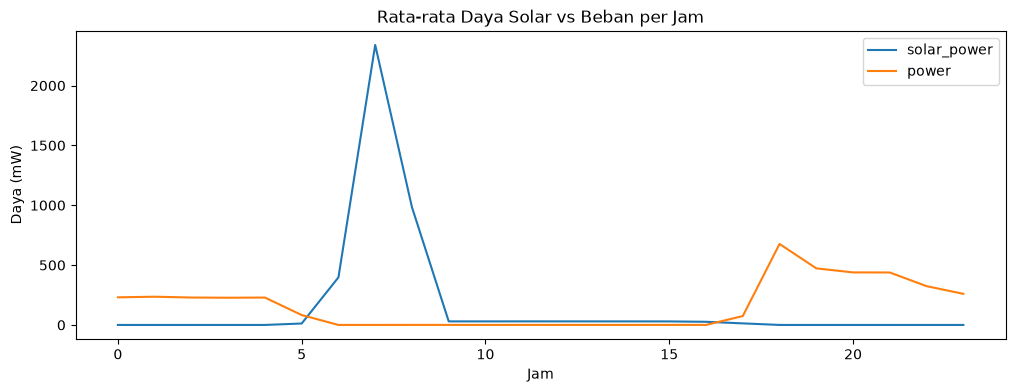

In [6]:
# Pola harian: siang panel mengisi baterai, malam lampu menyala
hourly = df.groupby(df['time'].dt.hour)[['solar_power', 'power', 'lux']].mean()
fig, ax = plt.subplots(figsize=(12, 4))
hourly[['solar_power', 'power']].plot(ax=ax)
ax.set_xlabel('Jam'); ax.set_ylabel('Daya (mW)'); ax.set_title('Rata-rata Daya Solar vs Beban per Jam')
plt.show()

### Checking For Outliers

Memeriksa nilai ekstrem di setiap kolom numerik.

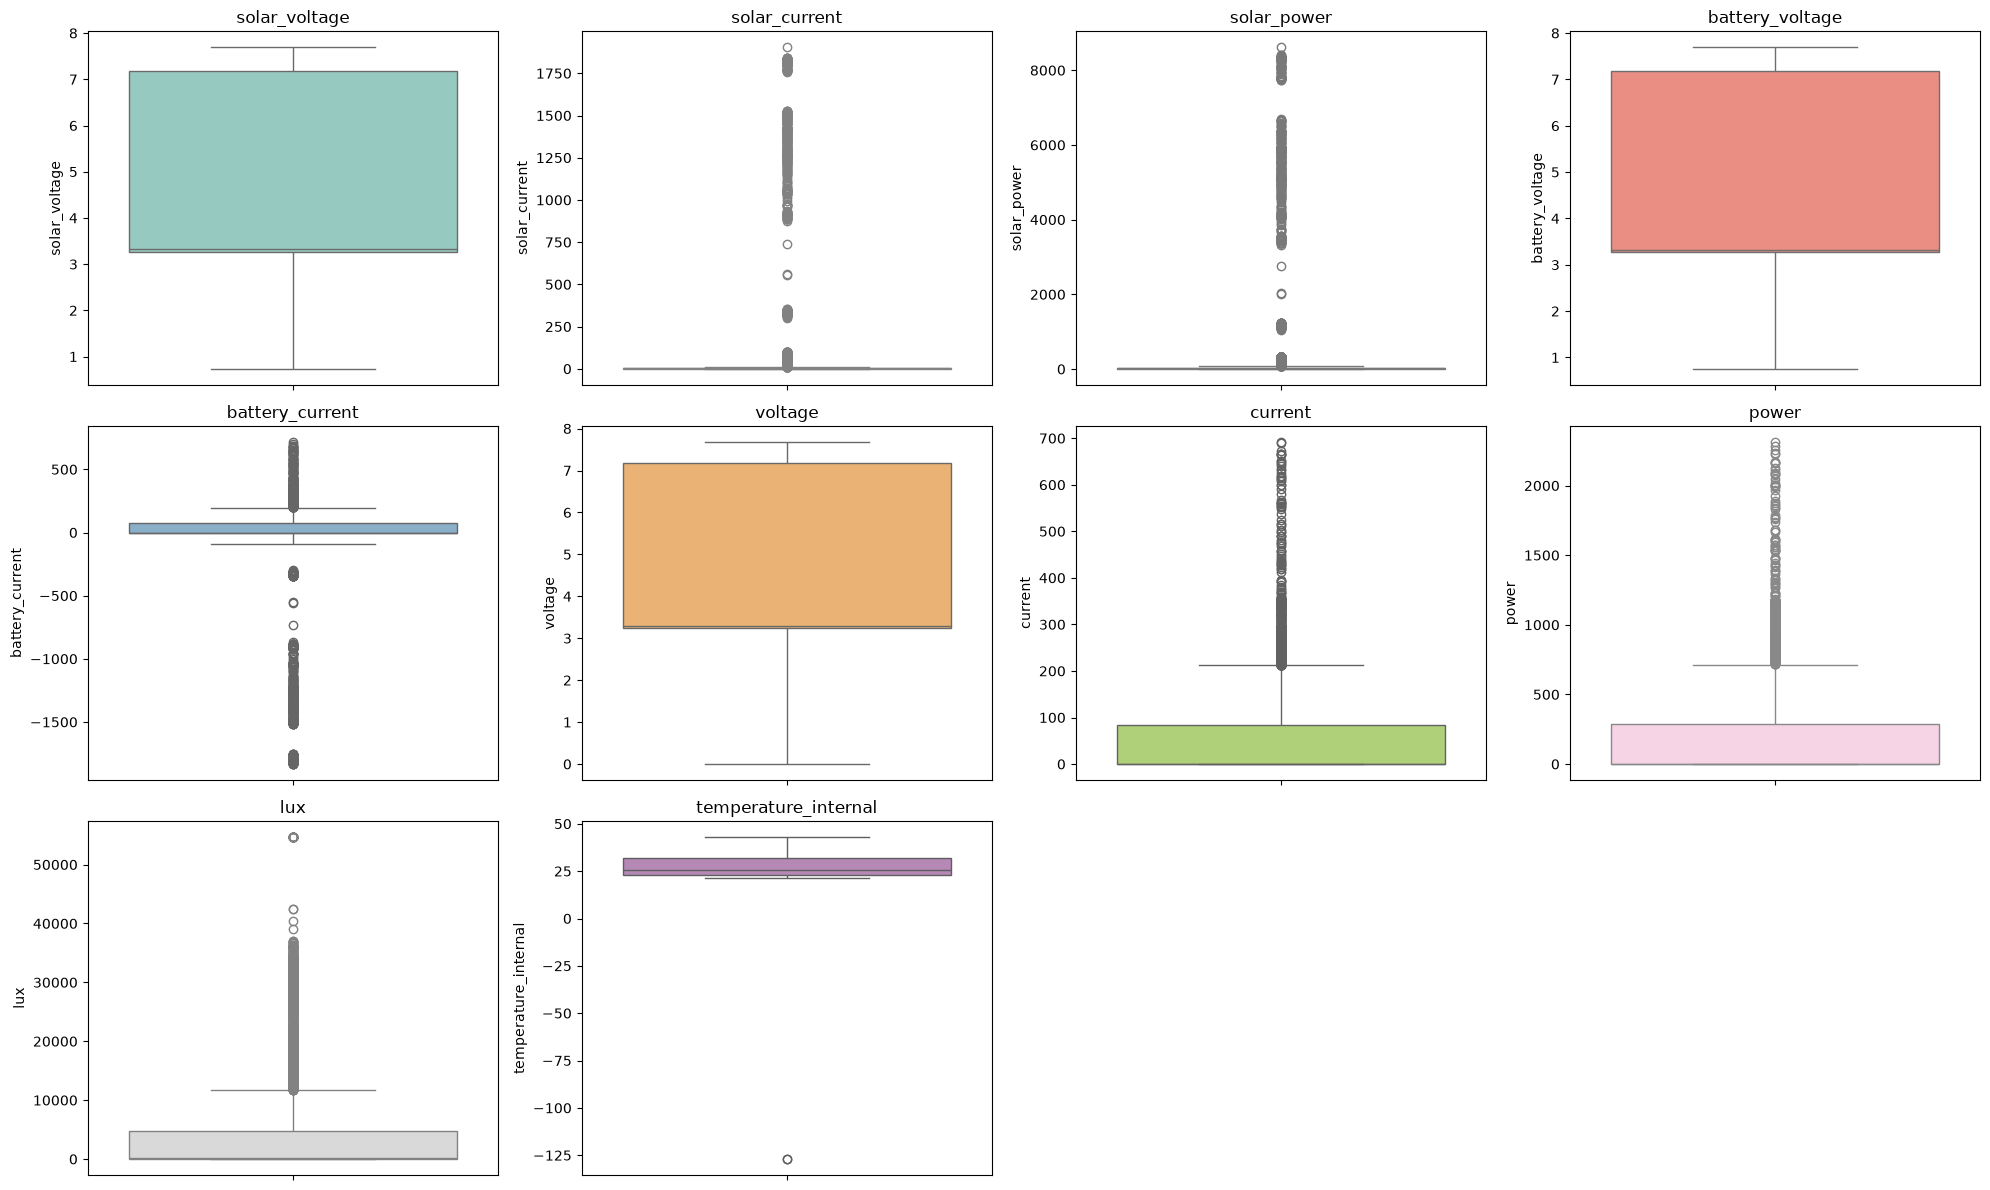

In [7]:
columns = [c for c in df.columns if c != 'time']
rows = (len(columns) + 3) // 4
plt.figure(figsize=(20, rows * 4))
colour = sns.color_palette('Set3', len(columns))
for i, col in enumerate(columns):
    plt.subplot(rows, 4, i + 1)
    sns.boxplot(y=df[col], color=colour[i])
    plt.title(col)
plt.tight_layout()
plt.show()

### Outliers Treatment

Berbeda dengan dataset stress siswa, outlier di sini **tidak di-capping**. Nilai ekstrem seperti suhu `-127` atau tegangan baterai `0.75 V` justru adalah **tanda kerusakan** yang ingin dideteksi model. Kalau di-capping dengan IQR, informasi kerusakan itu hilang.

In [8]:
print('Sampel suhu sensor error (< -50 °C):', (df['temperature_internal'] < -50).sum())
print('Sampel baterai drop (< 2.5 V)       :', (df['battery_voltage'] < 2.5).sum())
print('Sampel suhu tinggi (> 40 °C)        :', (df['temperature_internal'] > 40).sum())

Sampel suhu sensor error (< -50 °C): 2
Sampel baterai drop (< 2.5 V)       : 15
Sampel suhu tinggi (> 40 °C)        : 62


# Feature Engineering & Pelabelan

Dataset mentah **tidak memiliki label**, jadi label kondisi dibuat dari aturan domain:

| Label | Kondisi | Aturan |
|---|---|---|
| **0** | Normal | tidak ada aturan di bawah yang terpenuhi |
| **1** | Perlu Perhatian | baterai 2.5–3.2 V, suhu > 40 °C, atau lampu menyala < 50% waktu saat malam |
| **2** | Gangguan | baterai < 2.5 V, sensor suhu error (-127), atau lampu mati total saat malam padahal baterai cukup |

Fitur rolling (jendela 20 sampel ≈ 5 menit) ditambahkan agar model melihat tren, bukan hanya satu titik.

In [9]:
X = build_features(df)
y = label_condition(X)
X.head()

,solar_voltage,solar_current,solar_power,battery_voltage,battery_current,voltage,current,power,lux,temperature_internal,is_night,load_on,lamp_on_ratio_night,load_current_mean,battery_voltage_mean,battery_voltage_min,temperature_max,solar_power_mean
0,4.39,1764.8,7750.0,3.96,-1755.7,4.16,0.0,4.0,20078.33,36.00,0,0,1.0,0.0,3.9600,3.96,36.00,7750.000000
1,4.40,1766.8,7770.0,3.96,-1758.3,4.17,0.0,0.0,19875.00,36.13,0,0,1.0,0.0,3.9600,3.96,36.13,7760.000000
2,4.40,1772.3,7798.0,3.96,-1763.0,4.17,0.0,0.0,19954.17,36.00,0,0,1.0,0.0,3.9600,3.96,36.13,7772.666667
3,4.40,1771.4,7796.0,3.97,-1761.7,4.17,0.0,0.0,19985.00,35.81,0,0,1.0,0.0,3.9625,3.96,36.13,7778.500000
4,4.40,1770.2,7790.0,3.96,-1761.1,4.17,0.0,0.0,19967.50,35.63,0,0,1.0,0.0,3.9620,3.96,36.13,7780.800000


In [10]:
print(y.map(LABEL_NAMES).value_counts())

Normal             10764
Perlu Perhatian      691
Gangguan              31
Name: count, dtype: int64


# Menerapkan Model Random Forest dan Split Data

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=500, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                               class_weight='balanced', random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=500, n_jobs=-1,
                       random_state=42)

In [12]:
y_train.value_counts(normalize=True)

0    0.937092
1    0.060187
2    0.002721
Name: proportion, dtype: float64

# Menguji Hasil Test dan Evaluasi

In [13]:
y_pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))

Accuracy: 1.0


Classification Report
                 precision    recall  f1-score   support

         Normal       1.00      1.00      1.00      2154
Perlu Perhatian       1.00      1.00      1.00       138
       Gangguan       1.00      1.00      1.00         6

       accuracy                           1.00      2298
      macro avg       1.00      1.00      1.00      2298
   weighted avg       1.00      1.00      1.00      2298



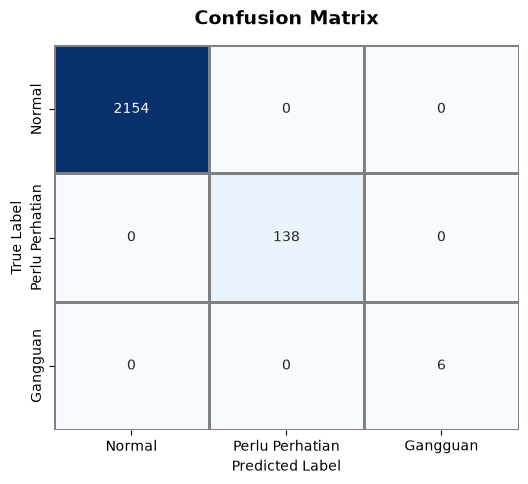

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
labels = sorted(LABEL_NAMES)
print('Classification Report')
print(classification_report(y_test, y_pred, labels=labels, target_names=[LABEL_NAMES[i] for i in labels], zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=1, linecolor='gray',
            xticklabels=[LABEL_NAMES[i] for i in labels], yticklabels=[LABEL_NAMES[i] for i in labels])
plt.title('Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.show()

**Catatan penting:** akurasi akan sangat tinggi (≈100%) karena label dibuat dari aturan pada fitur yang sama — model sedang *mempelajari aturan* tersebut. Agar model benar-benar prediktif, label sebaiknya diganti dengan catatan kerusakan/perawatan nyata dari tiket maintenance.

# Feature Importance

                 Feature  Importance
12   lamp_on_ratio_night    0.245207
1          solar_current    0.089317
9   temperature_internal    0.077560
8                    lux    0.075508
16       temperature_max    0.071713
13     load_current_mean    0.069242
3        battery_voltage    0.061459
14  battery_voltage_mean    0.051477
5                voltage    0.050630
15   battery_voltage_min    0.049812
17      solar_power_mean    0.047690
0          solar_voltage    0.045735
10              is_night    0.025861
4        battery_current    0.014530
2            solar_power    0.013917
6                current    0.005230
7                  power    0.003728
11               load_on    0.001386


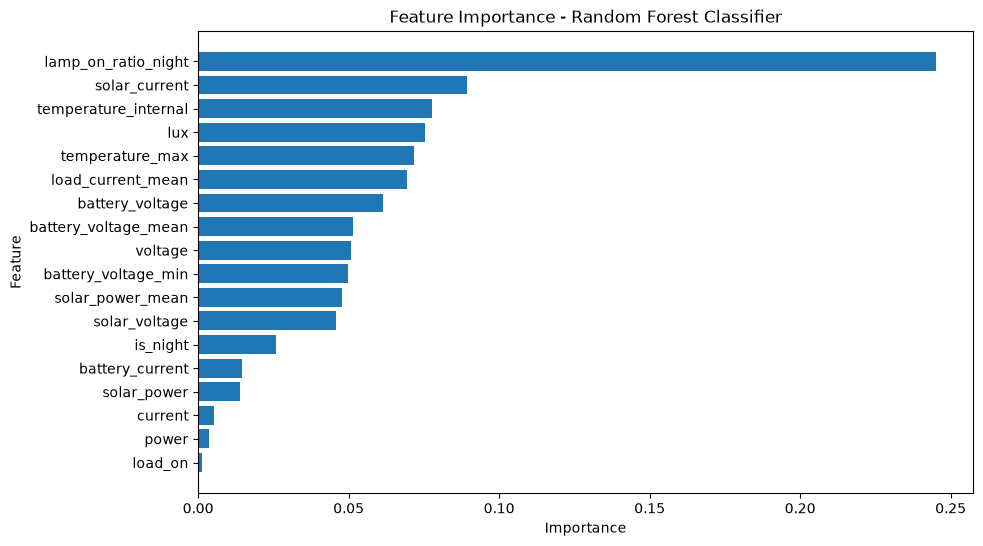

In [15]:
importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': model.feature_importances_}) \
    .sort_values(by='Importance', ascending=False)
print(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.gca().invert_yaxis()
plt.xlabel('Importance'); plt.ylabel('Feature')
plt.title('Feature Importance - Random Forest Classifier')
plt.show()

# Testing Model dengan Contoh Data

In [16]:
def contoh(n=20, **override):
    base = dict(solar_voltage=3.3, solar_current=0.0, solar_power=0.0, battery_voltage=3.3, battery_current=90.0,
                voltage=3.3, current=90.0, power=300.0, lux=2.0, temperature_internal=25.0)
    return build_features(pd.DataFrame([{**base, **override}] * n)).tail(1)

# 🟢 Normal: malam hari, baterai 3.3 V, lampu menyala
print('Normal          :', LABEL_NAMES[model.predict(contoh())[0]])
# 🟡 Perlu Perhatian: baterai mulai rendah 3.1 V
print('Perlu Perhatian :', LABEL_NAMES[model.predict(contoh(battery_voltage=3.1))[0]])
# 🔴 Gangguan: baterai drop 0.8 V, lampu mati
print('Gangguan        :', LABEL_NAMES[model.predict(contoh(battery_voltage=0.8, voltage=0, current=0, power=0))[0]])

Normal          : Normal
Perlu Perhatian : Perlu Perhatian


Gangguan        : Gangguan


# Simpan Model

Format yang disimpan sama dengan `python -m app.ml.train`, sehingga langsung dipakai Celery task `run_ml_prediction`.

In [17]:
from app.ml.train import save_model
result = {'model': model, 'accuracy': accuracy_score(y_test, y_pred),
          'f1_macro': __import__('sklearn.metrics', fromlist=['f1_score']).f1_score(y_test, y_pred, average='macro')}
out = BACKEND_DIR / 'ml_models' / 'failure_predictor.joblib'
save_model(result, out, {LABEL_NAMES[k]: int(v) for k, v in y.value_counts().items()})
print(f"Model berhasil disimpan ke '{out}'")

Model berhasil disimpan ke '/home/diazadr/Project/street-lamp-predictive-maintenance/backend/ml_models/failure_predictor.joblib'
